**Eye-Tracking & Neurocognitive Intelligence | Eye-Movement Modelling & Advanced AI | Presented by: Reza Saadatyar (2026)**

**3 | 1D-CNN and Temporal Convolutional Network**

![Independent temporal model architectures and validation within source-participant partitions](../../images/03_cnn_and_tcn_models.svg)

**Objective:** Train and compare 1D-CNN and Temporal Convolutional Network (TCN) as independent compact temporal gaze classifiers. Each model has its own training cell, parameter count, learning curves, Validation confusion matrix and numerical record-level evaluation.

**Source and partitions:** The original GazeBase recording/task identities, four motion channels and train-only normalisation are fixed by Notebook 01. No Test results or Test-driven hyperparameters are used. Training and Validation windows inherit their source recording labels but **are not independent people**.

**Recorded pilot Validation:** Both models correctly classified **8/8 source recordings from two independent Validation people**, with **Accuracy, Macro F1 and Balanced Accuracy of 1.00**. The 1D-CNN checkpoint was selected at **epoch 8** (11,492 trainable parameters); the TCN checkpoint at **epoch 5** (12,772 parameters). Both models were trained for a maximum of eight epochs, with record-level Validation Macro F1 used for checkpoint selection. These results do **not** demonstrate independent Test performance, stability across people or architectural superiority.


**00. Colab Repository Setup**


In [ ]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**


In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("eye_movement_modelling")

# -------------------- 2. Temporal Training and Evaluation --------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from IPython.display import display
from core.stage_outputs import ensure_stage_inputs
from core.output_download import download_outputs_from_colab
from core.plot_style import plot_style, save_figure

# ------------------------- 3. Study Model Utilities --------------------------
from s2_data import (
    TASKS, load_protocol, load_windows, verify_temporal_source_alignment,
)
from s2_training import fit_temporal
from s2_metrics import metric_row

# ----------------------------- 4. Output Folder ------------------------------
output_dir = root / "eye_movement_modelling" / "output"
output_dir.mkdir(parents=True, exist_ok=True)
plot_style(font_family="DejaVu Sans", figure_dpi=100)
print("Eye-Movement Modelling temporal outputs:", output_dir)


Repository up to date.
Eye-Movement Modelling temporal outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/eye_movement_modelling/output


**02. Recover Normalised Windows and Frozen Participant Groups**

Reuse the same `01_sequence_windows.npz`, `01_split_assignments.csv` and `01_protocol.csv` as the classical comparison. Stage 01 computed normalisation moments **from Train windows only**; each temporal model receives exactly the same precomputed values. Both models in this notebook aggregate window probabilities **within each original source recording** before scoring.

In a fresh Colab Runtime, upload `eye_movement_modelling_Notebook_01_Outputs.zip` to `/content/` before this section; in the same Runtime, reuse existing stage-01 files. The recorded tensor contains **960 windows (256 time steps × 4 channels)**: **576 Train, 192 Validation and 192 reserved pilot Test** windows. The eight Validation records belong to **two independent people**. No per-window partitioning or Test-based selection is performed.


In [3]:
# ==================== 02. Recover Frozen Temporal Inputs =====================

# -------------------- 1. Restore Explicit Stage 01 Files ---------------------
ensure_stage_inputs(output_dir, 1, (
    "01_sequence_windows.npz",
    "01_split_assignments.csv", "01_protocol.csv",
))
windows = load_windows(output_dir / "01_sequence_windows.npz")
split = pd.read_csv(
    output_dir / "01_split_assignments.csv",
    dtype={"record_id": str, "participant_id": str},
)
protocol = load_protocol(output_dir / "01_protocol.csv")
if windows["x"].shape[1:] != (
    protocol["window_samples"], len(protocol["temporal_channels"]),
):
    raise ValueError("Sequence data does not match the saved source protocol")

# -------------------------- 2. Display Data Support --------------------------
record_roles = dict(zip(split.record_id, split.split))
alignment_counts = verify_temporal_source_alignment(windows, split)
roles = np.array([record_roles[str(r)] for r in windows["record_id"]])
print("Verified window counts by participant partition:", alignment_counts)
validation_people = split.loc[
    split.split.eq("validation"), "participant_id",
].nunique()
print("Study mode:", protocol["purpose"])
print("Sequence tensor:", windows["x"].shape)
print("Train/Validation/Test window counts:")
display(pd.Series(roles).value_counts().rename("n_windows").to_frame())
print("Independent Validation participants:", validation_people)
reported = []


Verified window counts by participant partition: {'train': 576, 'validation': 192, 'test': 192}
Study mode: pilot
Sequence tensor: (960, 256, 4)
Train/Validation/Test window counts:


,n_windows
train,576
test,192
validation,192


Independent Validation participants: 2


**03. 1D-CNN Architecture, Training and Validation**

**Architecture:** Two compact Conv1d layers with nonlinear activation and temporal pooling summarise local variations in the gaze sequence. The input is a fixed-length tensor of consecutive, source-valid gaze samples with four train-normalised channels. The executed run selected **epoch 8/8**, with **11,492 trainable parameters**. The model correctly classified **8/8 Validation records** (record-level Accuracy, Macro F1 and Balanced Accuracy each **1.00**). The observed losses decreased over the recorded epochs; this is pilot evidence only.

**Caution:** Validation is a small participant-level group. Its metric is for provisional selection only, not an independently replicated result.


Model: cnn
Best epoch: 8
Trainable parameters: 11492


,model,partition,n_records,n_participants,accuracy,macro_f1,balanced_accuracy,epoch,train_loss,validation_window_loss
0,cnn,validation,8,2,0.375,0.309524,0.375,1,1.378137,1.359961
1,cnn,validation,8,2,0.250,0.125000,0.250,2,1.351343,1.340908
2,cnn,validation,8,2,0.375,0.309524,0.375,3,1.330440,1.324197
3,cnn,validation,8,2,0.625,0.550000,0.625,4,1.310881,1.310591
4,cnn,validation,8,2,0.750,0.666667,0.750,5,1.293278,1.298612
5,cnn,validation,8,2,1.000,1.000000,1.000,6,1.279468,1.289480
6,cnn,validation,8,2,1.000,1.000000,1.000,7,1.267232,1.286137
7,cnn,validation,8,2,1.000,1.000000,1.000,8,1.255630,1.277611


,model,partition,n_records,n_participants,accuracy,macro_f1,balanced_accuracy,parameters,best_epoch
0,cnn,validation,8,2,1.0,1.0,1.0,11492,8


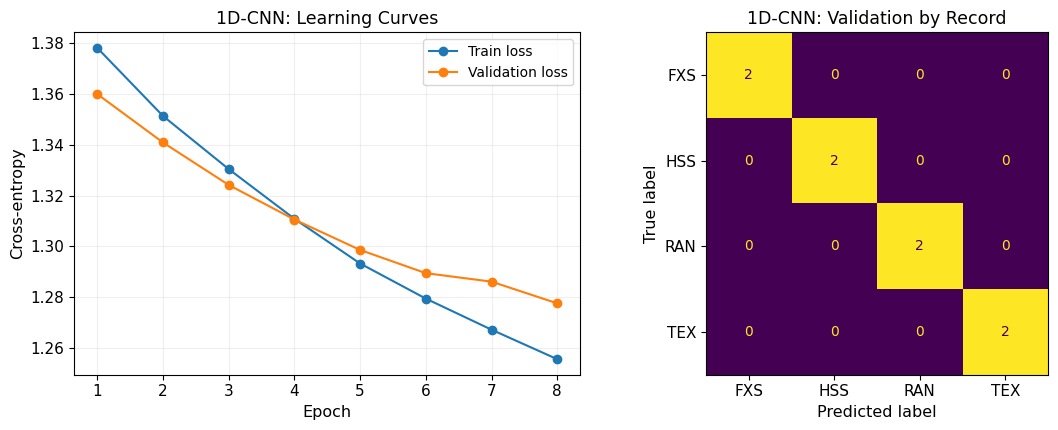

In [4]:
# ============================= 03. Train 1D-CNN ==============================

# --------------------- 1. Fit on Train Participants Only ---------------------
model_name = "cnn"
history, predictions, info = fit_temporal(
    model_name, windows, split, output_dir / f"03_cnn.pt",
    seed=protocol["split_seed"], epochs=8, patience=3,
    batch_size=64,
)
history.to_csv(output_dir / f"03_cnn_history.csv", index=False)
predictions.to_csv(
    output_dir / f"03_cnn_validation_predictions.csv", index=False,
)
print("Model:", model_name)
print("Best epoch:", info["best_epoch"])
print("Trainable parameters:", info["parameters"])
display(history.tail(8))

# --------------------- 2. Report Record-Level Validation ---------------------
result = metric_row(
    predictions["target_index"], predictions["pred_index"],
    model=model_name, partition="validation",
    n_participants=validation_people,
)
result["parameters"] = int(info["parameters"])
result["best_epoch"] = int(info["best_epoch"])
reported.append(result)
display(pd.DataFrame([result]))

# ------------------ 3. Display Learning and Error Evidence -------------------
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
axes[0].plot(history["epoch"], history["train_loss"],
             marker="o", label="Train loss")
axes[0].plot(history["epoch"], history["validation_window_loss"],
             marker="o", label="Validation loss")
axes[0].set(xlabel="Epoch", ylabel="Cross-entropy",
            title="1D-CNN: Learning Curves")
axes[0].grid(alpha=0.2)
axes[0].legend()
matrix = confusion_matrix(
    predictions.target_index, predictions.pred_index,
    labels=range(len(TASKS)),
)
ConfusionMatrixDisplay(matrix, display_labels=TASKS).plot(
    ax=axes[1], colorbar=False, values_format="d",
)
axes[1].set_title("1D-CNN: Validation by Record")
fig.tight_layout()
save_figure(fig, output_dir / f"03_cnn_evaluation.png")
plt.show()


**04. Temporal Convolutional Network (TCN) Architecture, Training and Validation**

**Architecture:** A residual stack with dilations 1, 2 and 4 captures longer temporal context within each offline window; this implementation is non-causal. Use the same time windows, group split, seed, optimiser family and maximum epoch budget as the preceding model, while preserving model-specific mechanisms.

The executed run selected **epoch 5/8**, with **12,772 trainable parameters**, and classified **8/8 Validation records** correctly (record-level Accuracy, Macro F1 and Balanced Accuracy each **1.00**). Later epochs had lower window-level loss but worse record-level Macro F1, so checkpoint selection followed the specified record-level metric rather than minimum window loss. Model features are not automatically faithful explanations of task decisions.


Model: tcn
Best epoch: 5
Trainable parameters: 12772


,model,partition,n_records,n_participants,accuracy,macro_f1,balanced_accuracy,epoch,train_loss,validation_window_loss
0,tcn,validation,8,2,0.375,0.291667,0.375,1,1.372892,1.357614
1,tcn,validation,8,2,0.500,0.342857,0.500,2,1.344528,1.339748
2,tcn,validation,8,2,0.375,0.277778,0.375,3,1.327845,1.324658
3,tcn,validation,8,2,0.750,0.650000,0.750,4,1.311064,1.311017
4,tcn,validation,8,2,1.000,1.000000,1.000,5,1.293229,1.298460
5,tcn,validation,8,2,0.875,0.866667,0.875,6,1.276603,1.287932
6,tcn,validation,8,2,0.750,0.650000,0.750,7,1.259920,1.281928
7,tcn,validation,8,2,0.875,0.866667,0.875,8,1.242608,1.265481


,model,partition,n_records,n_participants,accuracy,macro_f1,balanced_accuracy,parameters,best_epoch
0,tcn,validation,8,2,1.0,1.0,1.0,12772,5


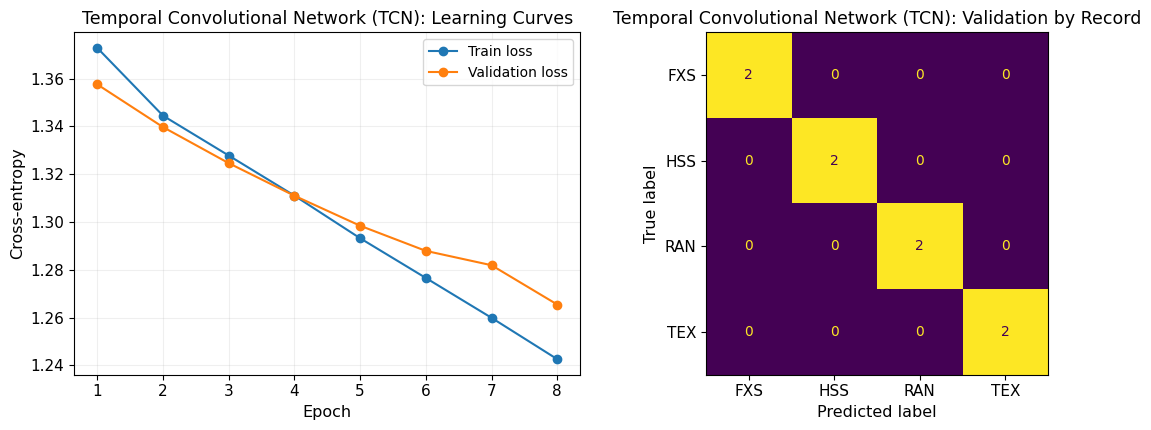

In [5]:
# ============== 04. Train Temporal Convolutional Network (TCN) ===============

# --------------------- 1. Fit on Train Participants Only ---------------------
model_name = "tcn"
history, predictions, info = fit_temporal(
    model_name, windows, split, output_dir / f"03_tcn.pt",
    seed=protocol["split_seed"], epochs=8, patience=3,
    batch_size=64,
)
history.to_csv(output_dir / f"03_tcn_history.csv", index=False)
predictions.to_csv(
    output_dir / f"03_tcn_validation_predictions.csv", index=False,
)
print("Model:", model_name)
print("Best epoch:", info["best_epoch"])
print("Trainable parameters:", info["parameters"])
display(history.tail(8))

# --------------------- 2. Report Record-Level Validation ---------------------
result = metric_row(
    predictions["target_index"], predictions["pred_index"],
    model=model_name, partition="validation",
    n_participants=validation_people,
)
result["parameters"] = int(info["parameters"])
result["best_epoch"] = int(info["best_epoch"])
reported.append(result)
display(pd.DataFrame([result]))

# ------------------ 3. Display Learning and Error Evidence -------------------
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
axes[0].plot(history["epoch"], history["train_loss"],
             marker="o", label="Train loss")
axes[0].plot(history["epoch"], history["validation_window_loss"],
             marker="o", label="Validation loss")
axes[0].set(xlabel="Epoch", ylabel="Cross-entropy",
            title="Temporal Convolutional Network (TCN): Learning Curves")
axes[0].grid(alpha=0.2)
axes[0].legend()
matrix = confusion_matrix(
    predictions.target_index, predictions.pred_index,
    labels=range(len(TASKS)),
)
ConfusionMatrixDisplay(matrix, display_labels=TASKS).plot(
    ax=axes[1], colorbar=False, values_format="d",
)
axes[1].set_title("Temporal Convolutional Network (TCN): Validation by Record")
fig.tight_layout()
save_figure(fig, output_dir / f"03_tcn_evaluation.png")
plt.show()


**05. Compare the Two Temporal Models on Record-Level Validation**

Both saved checkpoints achieved **Accuracy = Macro F1 = Balanced Accuracy = 1.00** on the same **eight recordings from two Validation participants**. CNN has **11,492 parameters (selected epoch 8)** and TCN has **12,772 (selected epoch 5)**. The CSV retains these metrics and model details. The tied scores neither favour one architecture nor establish generalisation beyond this development pilot.

Notebook 05 later compares these scores to the feature-based and other temporal families. It makes the selected-model decision from **Validation only**, before opening Test results.


,model,partition,n_records,n_participants,accuracy,macro_f1,balanced_accuracy,parameters,best_epoch
0,cnn,validation,8,2,1.0,1.0,1.0,11492,8
1,tcn,validation,8,2,1.0,1.0,1.0,12772,5


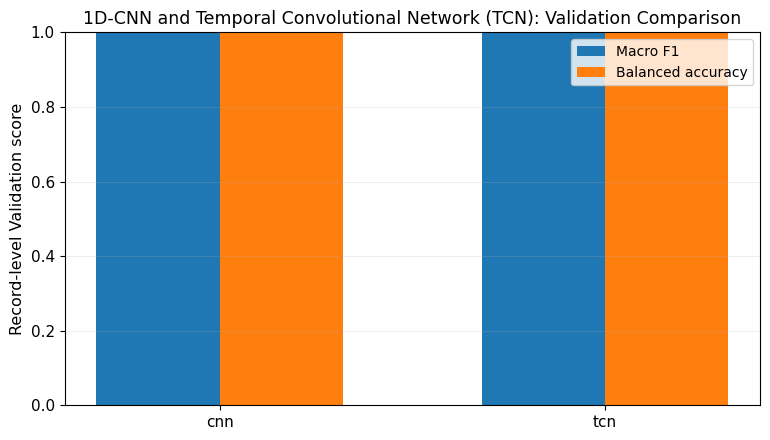

In [6]:
# ====================== 05. Compare Temporal Validation ======================

# --------------------- 1. Save Shared Validation Metrics ---------------------
metrics = pd.DataFrame(reported).sort_values(
    ["macro_f1", "balanced_accuracy", "model"],
    ascending=[False, False, True],
)
metrics.to_csv(
    output_dir / "03_neural_validation_metrics.csv", index=False,
)
display(metrics)

# --------------------- 2. Plot Independent Model Scores ----------------------
fig, ax = plt.subplots(figsize=(7.8, 4.5))
pos = np.arange(len(metrics))
ax.bar(pos - 0.16, metrics["macro_f1"], 0.32, label="Macro F1")
ax.bar(pos + 0.16, metrics["balanced_accuracy"], 0.32,
       label="Balanced accuracy")
ax.set_xticks(pos, metrics["model"])
ax.set(ylabel="Record-level Validation score", ylim=(0, 1),
       title="1D-CNN and Temporal Convolutional Network (TCN): Validation Comparison")
ax.legend()
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
save_figure(fig, output_dir / "03_model_comparison.png")
plt.show()


**06. Interpretation and Local Model Outputs**

The recorded execution produced **10 stage-03 files**: two saved checkpoints, two histories, two record-level Validation prediction tables, two assessment figures, a shared Validation metrics table and a comparison figure. Checkpoint selection was based on Validation; **no Test scores were computed** here.

The final cell only packages stage-03 files, letting the ZIP helper print its file list once. Preserve the resulting `eye_movement_modelling_Notebook_03_Outputs.zip` for Notebook 05. Notebook 04 reads compatible inputs from Notebook 01 and does not require the Notebook 03 ZIP. Model outputs may now be staged in Git after review, subject to the independent 50,000,000-byte blob policy.


In [ ]:
# ======================= 06. Export Stage-03 Evidence ========================

# ------------------------ 1. Package Current Outputs -------------------------
# The helper prints the output list and ZIP location once.
download_outputs_from_colab("eye_movement_modelling/output", "03")


------------------------------------------------------------------------
Notebook 03
Files packaged: 10
  + 03_cnn.pt
  + 03_cnn_evaluation.png
  + 03_cnn_history.csv
  + 03_cnn_validation_predictions.csv
  + 03_model_comparison.png
  + 03_neural_validation_metrics.csv
  + 03_tcn.pt
  + 03_tcn_evaluation.png
  + 03_tcn_history.csv
  + 03_tcn_validation_predictions.csv
Download ZIP from Colab Contents: /content/eye_movement_modelling_Notebook_03_Outputs.zip
